# 🎯 Accident Risk Classification — Multi-Model Comparison

This notebook builds a **classification system** that predicts **accident severity** (Low / Medium / High) from road and environmental features.

**Workflow:**
1. Bin the continuous `accident_risk` target into severity classes
2. Bin `curvature` into intuitive categories for user-friendly input
3. Train **10 different classification algorithms**
4. Compare all models and identify the best performer
5. Tune the best model's hyperparameters
6. Provide an **interactive prediction interface** for user input

---

## 1 · Setup & Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ── Classifiers ──
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, ExtraTreesClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

%matplotlib inline

print('Libraries loaded successfully ✓')

Libraries loaded successfully ✓


## 2 · Load Data

In [ ]:
df = pd.read_csv('data/train.csv', low_memory=False)
print(f'Dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Columns: {list(df.columns)}')
df.head()

Dataset: 517,754 rows × 14 columns
Columns: ['id', 'road_type', 'num_lanes', 'curvature', 'speed_limit', 'lighting', 'weather', 'road_signs_present', 'public_road', 'time_of_day', 'holiday', 'school_season', 'num_reported_accidents', 'accident_risk']


,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,0,urban,2,0.06,35,daylight,rainy,False,True,afternoon,False,True,1,0.13
1,1,urban,4,0.99,35,daylight,clear,True,False,evening,True,True,0,0.35
2,2,rural,4,0.63,70,dim,clear,False,True,morning,True,False,2,0.30
3,3,highway,4,0.07,35,dim,rainy,True,True,morning,False,False,1,0.21
4,4,rural,1,0.58,60,daylight,foggy,False,False,evening,True,False,1,0.56


## 3 · Target Variable Engineering

The `accident_risk` column is continuous (0–1). We bin it into **3 severity classes** for classification:

| Class | Risk Range | Interpretation |
|-------|-----------|----------------|
| **Low** | 0.00 – 0.33 | Low-risk conditions |
| **Medium** | 0.34 – 0.66 | Moderate risk |
| **High** | 0.67 – 1.00 | High-risk conditions |

In [4]:
def bin_severity(risk_value):
    """Bin continuous accident_risk into 3 severity classes."""
    if risk_value <= 0.33:
        return 'Low'
    elif risk_value <= 0.66:
        return 'Medium'
    else:
        return 'High'

# Create target column
df['severity'] = df['accident_risk'].apply(bin_severity)

# Encode target as integers
label_encoder = LabelEncoder()
df['severity_encoded'] = label_encoder.fit_transform(df['severity'])

print('Target classes:', list(label_encoder.classes_))
print(f'Encoding: {dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}')
print()
print('Class distribution:')
print(df['severity'].value_counts().sort_index())
print()
print('Class proportions (%):')
print((df['severity'].value_counts(normalize=True).sort_index() * 100).round(2))

Target classes: ['High', 'Low', 'Medium']
Encoding: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}

Class distribution:
severity
High       22906
Low       247506
Medium    247342
Name: count, dtype: int64

Class proportions (%):
severity
High       4.42
Low       47.80
Medium    47.77
Name: proportion, dtype: float64


## 4 · Feature Engineering

### 4.1 Curvature Binning

The continuous `curvature` (0–1) is binned into intuitive categories for easier user input:

| Category | Range | Description |
|----------|-------|-------------|
| **Straight** | 0.00 – 0.20 | Nearly straight road |
| **Slight Curve** | 0.21 – 0.50 | Gentle bend |
| **Moderate Curve** | 0.51 – 0.80 | Notable curve |
| **Sharp Curve** | 0.81 – 1.00 | Tight/dangerous curve |

In [5]:
def bin_curvature(val):
    """Bin continuous curvature into 4 intuitive categories."""
    if val <= 0.20:
        return 'Straight'
    elif val <= 0.50:
        return 'Slight_Curve'
    elif val <= 0.80:
        return 'Moderate_Curve'
    else:
        return 'Sharp_Curve'

df['curvature_bin'] = df['curvature'].apply(bin_curvature)

print('Curvature bin distribution:')
print(df['curvature_bin'].value_counts())
print()

# Cross-tab: curvature bin vs severity
ct = pd.crosstab(df['curvature_bin'], df['severity'], normalize='index') * 100
print('Severity distribution (%) per curvature bin:')
print(ct.round(2))

Curvature bin distribution:
curvature_bin
Moderate_Curve    184992
Slight_Curve      152663
Straight          102026
Sharp_Curve        78073
Name: count, dtype: int64

Severity distribution (%) per curvature bin:
severity         High    Low  Medium
curvature_bin                       
Moderate_Curve   7.27  31.26   61.47
Sharp_Curve     11.12  20.20   68.68
Slight_Curve     0.46  61.61   37.93
Straight         0.07  78.27   21.66


### 4.2 Boolean Conversion & Feature Preparation

In [6]:
# Convert boolean columns to integer (0/1)
bool_cols = ['road_signs_present', 'public_road', 'holiday', 'school_season']
for col in bool_cols:
    df[col] = df[col].astype(int)

# Define feature groups
categorical_features = ['road_type', 'curvature_bin', 'lighting', 'weather', 'time_of_day']
numeric_features = ['num_lanes', 'speed_limit', 'num_reported_accidents']
boolean_features = ['road_signs_present', 'public_road', 'holiday', 'school_season']

all_features = categorical_features + numeric_features + boolean_features

print(f'Feature groups:')
print(f'  Categorical ({len(categorical_features)}): {categorical_features}')
print(f'  Numeric     ({len(numeric_features)}): {numeric_features}')
print(f'  Boolean     ({len(boolean_features)}): {boolean_features}')
print(f'  Total features: {len(all_features)}')

Feature groups:
  Categorical (5): ['road_type', 'curvature_bin', 'lighting', 'weather', 'time_of_day']
  Numeric     (3): ['num_lanes', 'speed_limit', 'num_reported_accidents']
  Boolean     (4): ['road_signs_present', 'public_road', 'holiday', 'school_season']
  Total features: 12


## 5 · Class Distribution Visualization

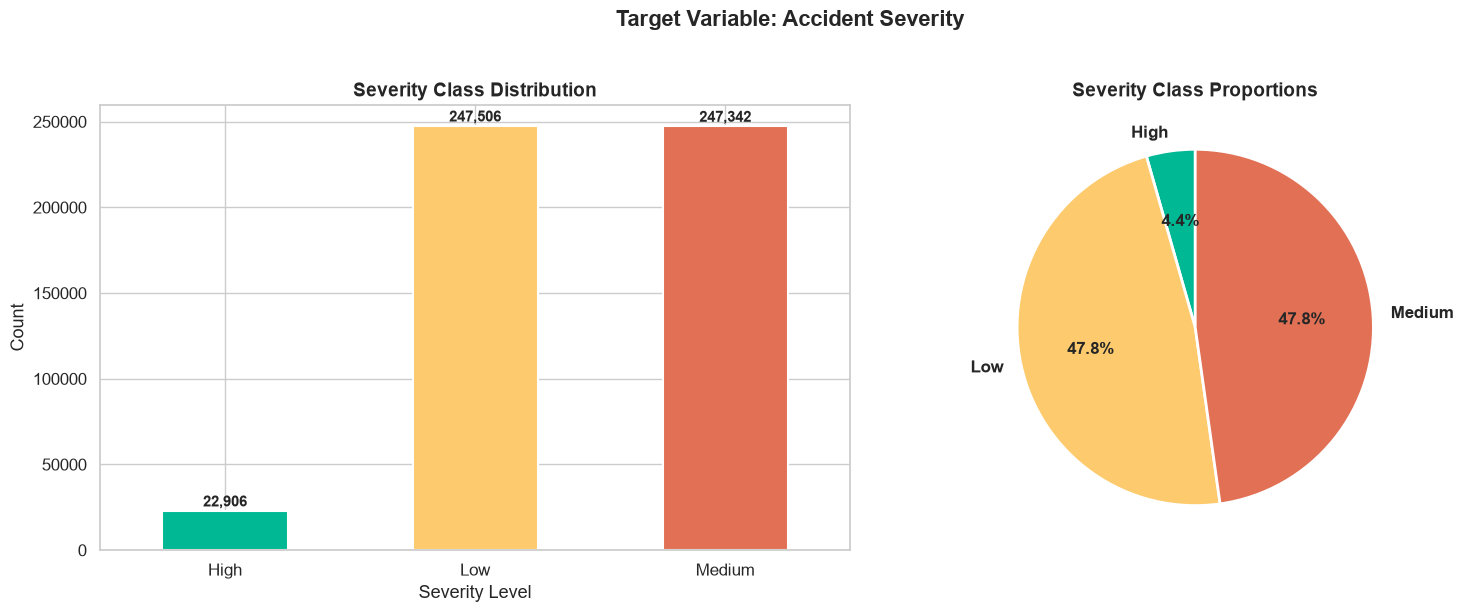

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of severity classes
colors = ['#00B894', '#FDCB6E', '#E17055']
severity_counts = df['severity'].value_counts().sort_index()
severity_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Severity Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Severity Level')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)
for i, (val, cnt) in enumerate(severity_counts.items()):
    axes[0].text(i, cnt + len(df)*0.005, f'{cnt:,}', ha='center', fontweight='bold', fontsize=11)

# Pie chart
axes[1].pie(severity_counts, labels=severity_counts.index, colors=colors,
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Severity Class Proportions', fontsize=14, fontweight='bold')

plt.suptitle('Target Variable: Accident Severity', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6 · Feature–Severity Relationships

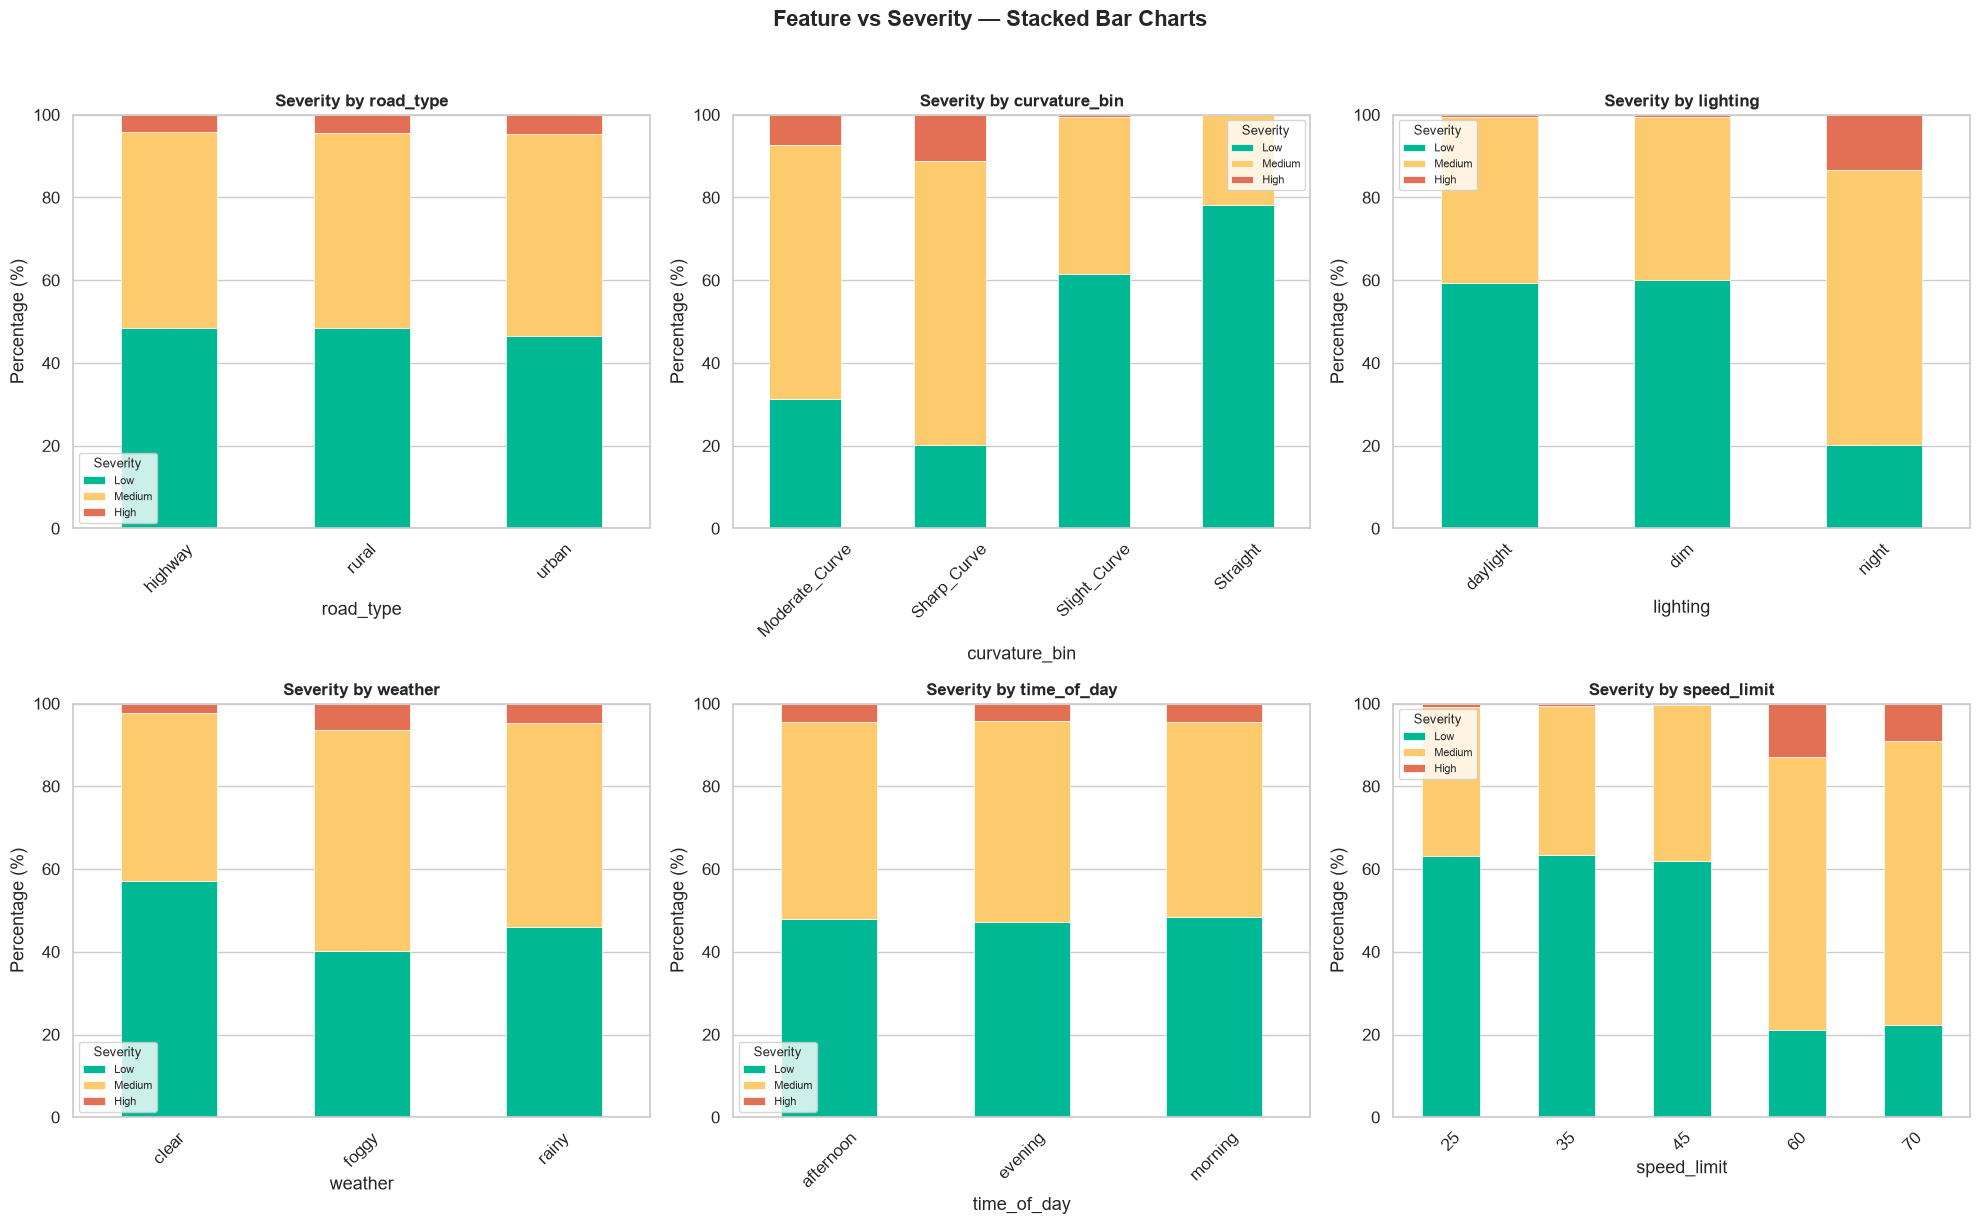

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

# Categorical features vs severity
cat_plot_cols = ['road_type', 'curvature_bin', 'lighting', 'weather', 'time_of_day', 'speed_limit']
palette = {'Low': '#00B894', 'Medium': '#FDCB6E', 'High': '#E17055'}

for i, col in enumerate(cat_plot_cols):
    ct = pd.crosstab(df[col], df['severity'], normalize='index') * 100
    ct = ct[['Low', 'Medium', 'High']]  # Ensure order
    ct.plot(kind='bar', stacked=True, ax=axes[i], color=[palette[c] for c in ct.columns],
            edgecolor='white', linewidth=0.5)
    axes[i].set_title(f'Severity by {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='Severity', fontsize=8, title_fontsize=9)
    axes[i].set_ylim(0, 100)

plt.suptitle('Feature vs Severity — Stacked Bar Charts', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

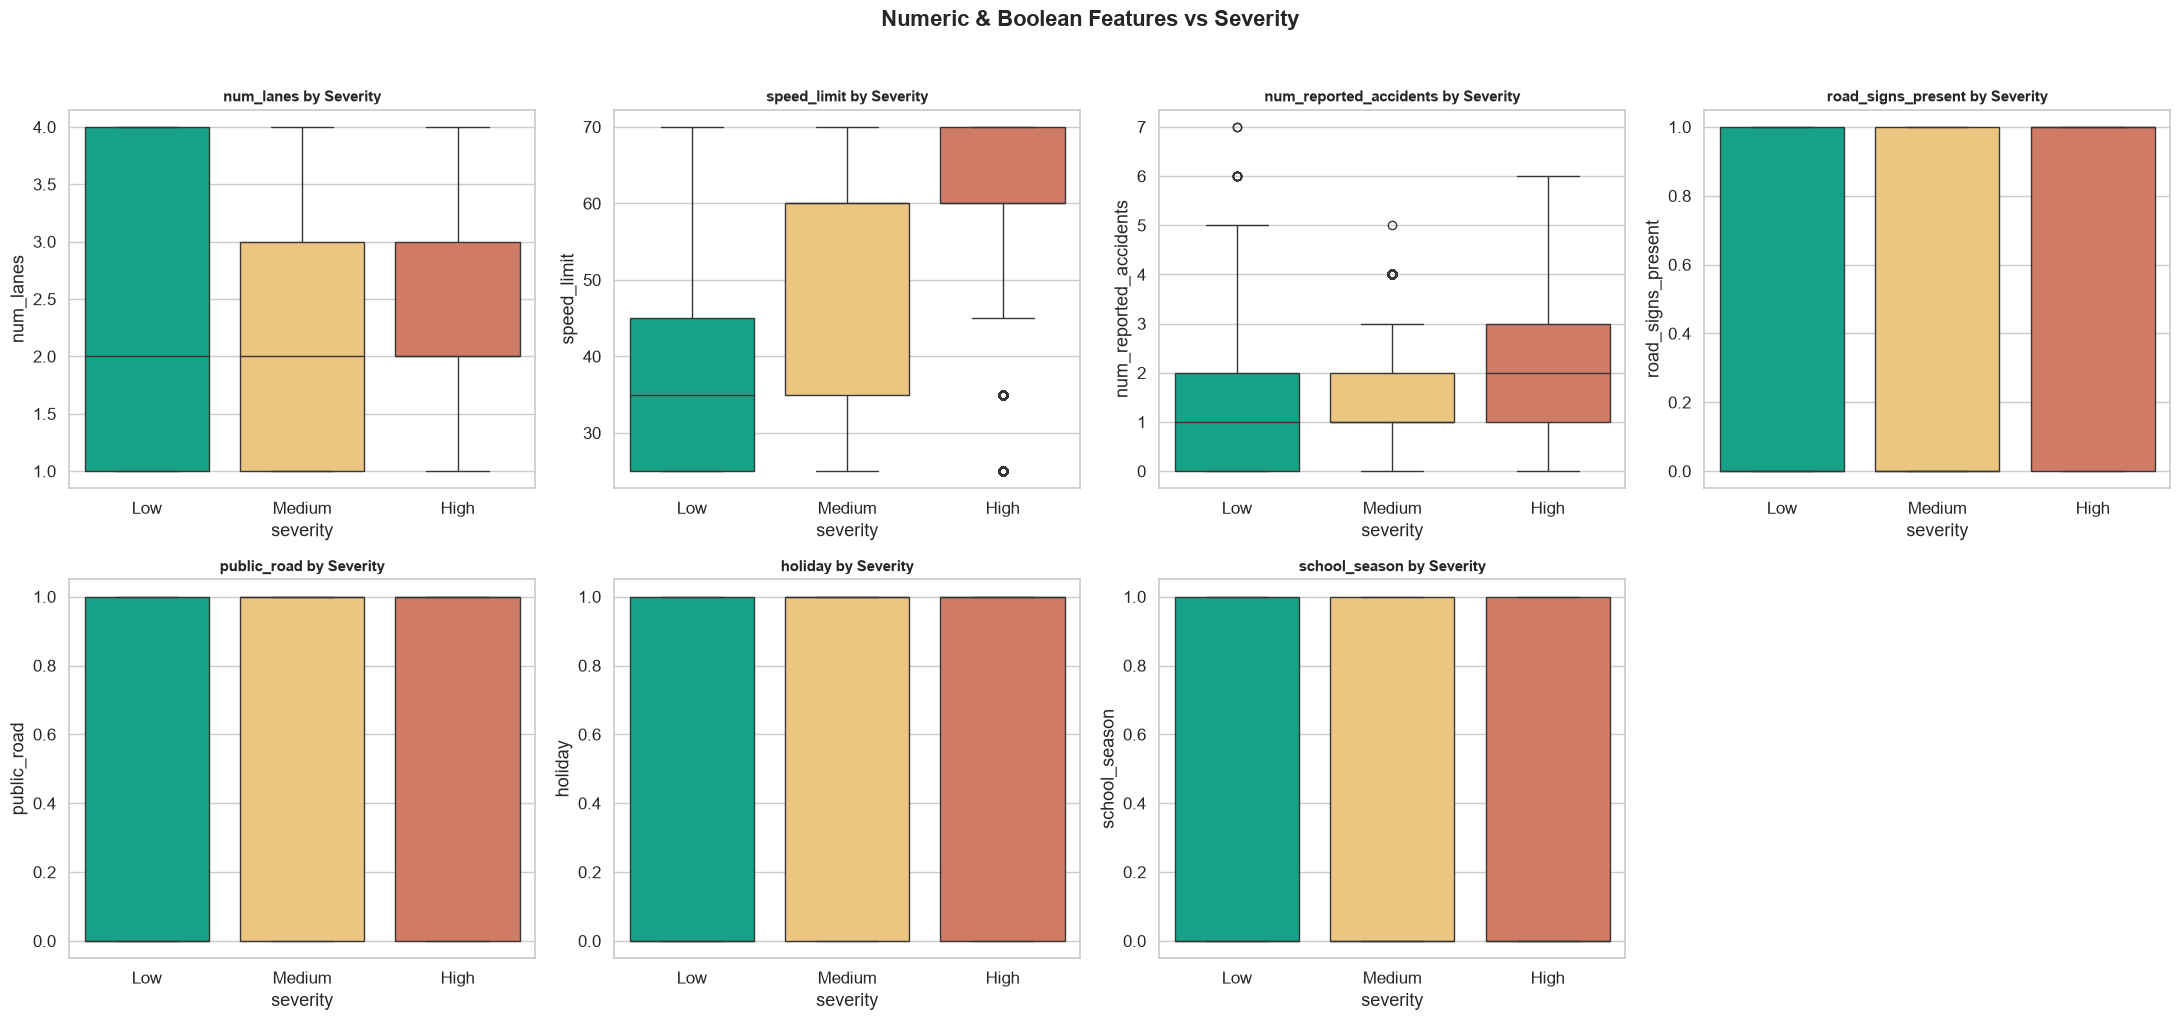

In [9]:
# Numeric & boolean features vs severity
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

num_bool_cols = numeric_features + boolean_features
for i, col in enumerate(num_bool_cols):
    if i < len(axes):
        sns.boxplot(data=df, x='severity', y=col, order=['Low', 'Medium', 'High'],
                    palette=palette, ax=axes[i])
        axes[i].set_title(f'{col} by Severity', fontsize=11, fontweight='bold')

# Hide unused axes
for j in range(len(num_bool_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numeric & Boolean Features vs Severity', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7 · Train / Test Split

We use a stratified 80/20 split to preserve class proportions.

In [10]:
# Prepare X and y
X = df[all_features].copy()
y = df['severity_encoded'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {X_train.shape[0]:,} samples')
print(f'Test set:     {X_test.shape[0]:,} samples')
print()
print('Class proportions (train):')
train_dist = pd.Series(y_train).map(dict(enumerate(label_encoder.classes_))).value_counts(normalize=True) * 100
print(train_dist.sort_index().round(2))
print()
print('Class proportions (test):')
test_dist = pd.Series(y_test).map(dict(enumerate(label_encoder.classes_))).value_counts(normalize=True) * 100
print(test_dist.sort_index().round(2))

Training set: 414,203 samples
Test set:     103,551 samples

Class proportions (train):
severity_encoded
High       4.42
Low       47.80
Medium    47.77
Name: proportion, dtype: float64

Class proportions (test):
severity_encoded
High       4.42
Low       47.80
Medium    47.77
Name: proportion, dtype: float64


## 8 · Preprocessing Pipeline

A `ColumnTransformer` handles encoding and scaling automatically:
- **Categorical** → One-Hot Encoding
- **Numeric** → Standard Scaling
- **Boolean** → Pass-through (already 0/1)

In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ('num', StandardScaler(), numeric_features),
        ('bool', 'passthrough', boolean_features)
    ],
    remainder='drop'
)

print('Preprocessing pipeline defined ✓')
print(f'  Categorical ({len(categorical_features)} cols) → OneHotEncoder')
print(f'  Numeric     ({len(numeric_features)} cols) → StandardScaler')
print(f'  Boolean     ({len(boolean_features)} cols) → Passthrough')

Preprocessing pipeline defined ✓
  Categorical (5 cols) → OneHotEncoder
  Numeric     (3 cols) → StandardScaler
  Boolean     (4 cols) → Passthrough


## 9 · Define Classification Models

We compare **10 diverse algorithms** spanning linear, tree-based, ensemble, distance-based, and neural approaches.

In [18]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, random_state=42, solver='lbfgs'
    ),
    'SGD Classifier': SGDClassifier(
        loss='modified_huber', max_iter=1000, random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=15, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=20, random_state=42, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42
    ),
    'AdaBoost': AdaBoostClassifier(
        n_estimators=150, learning_rate=0.5, random_state=42
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200, max_depth=20, random_state=42, n_jobs=-1
    ),
    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=7, n_jobs=-1
    ),
    'Linear SVM': LinearSVC(
        max_iter=2000, random_state=42
    ),
    'MLP Neural Network': MLPClassifier(
        hidden_layer_sizes=(128, 64, 32), max_iter=500,
        early_stopping=True, random_state=42
    ),
}

try:
    from xgboost import XGBClassifier
    models['XGBoost'] = XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        eval_metric='mlogloss',
        random_state=42, n_jobs=-1
    )
    print(f'XGBoost available — included! ({len(models)} models total)')
except ImportError:
    print(f'XGBoost not installed — skipping. ({len(models)} models total)')

print()
print('Models to compare:')
for i, name in enumerate(models, 1):
    print(f'  {i:2d}. {name}')

XGBoost available — included! (11 models total)

Models to compare:
   1. Logistic Regression
   2. SGD Classifier
   3. Decision Tree
   4. Random Forest
   5. Gradient Boosting
   6. AdaBoost
   7. Extra Trees
   8. K-Nearest Neighbors
   9. Linear SVM
  10. MLP Neural Network
  11. XGBoost


## 10 · Train & Evaluate All Models

Each model is wrapped in a `Pipeline` with the shared preprocessor. We evaluate on the held-out test set and record accuracy, precision, recall, F1, and training time.

In [19]:
results = []
trained_pipelines = {}

print('Training and evaluating models...')
print('=' * 80)

for name, model in models.items():
    print(f'\n▶ {name}...')
    
    # Build pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train
    t_start = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - t_start
    
    # Predict
    y_pred = pipeline.predict(X_test)
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    # Store results
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Train Time (s)': round(train_time, 2)
    })
    trained_pipelines[name] = pipeline
    
    print(f'  Accuracy: {acc:.4f} | F1: {f1:.4f} | Time: {train_time:.2f}s')

print('\n' + '=' * 80)
print('All models trained ✓')

Training and evaluating models...

▶ Logistic Regression...
  Accuracy: 0.8172 | F1: 0.8165 | Time: 9.94s

▶ SGD Classifier...
  Accuracy: 0.7957 | F1: 0.7784 | Time: 9.58s

▶ Decision Tree...
  Accuracy: 0.8406 | F1: 0.8404 | Time: 5.84s

▶ Random Forest...
  Accuracy: 0.8236 | F1: 0.8234 | Time: 74.50s

▶ Gradient Boosting...
  Accuracy: 0.8532 | F1: 0.8524 | Time: 1013.77s

▶ AdaBoost...
  Accuracy: 0.8369 | F1: 0.8294 | Time: 66.56s

▶ Extra Trees...
  Accuracy: 0.8220 | F1: 0.8218 | Time: 70.99s

▶ K-Nearest Neighbors...
  Accuracy: 0.8306 | F1: 0.8301 | Time: 0.76s

▶ Linear SVM...
  Accuracy: 0.7976 | F1: 0.7812 | Time: 4.39s

▶ MLP Neural Network...
  Accuracy: 0.8528 | F1: 0.8521 | Time: 101.11s

▶ XGBoost...
  Accuracy: 0.8535 | F1: 0.8528 | Time: 28.05s

All models trained ✓


## 11 · Results Comparison — Leaderboard

In [20]:
# Build results DataFrame sorted by F1-Score (most balanced metric)
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1  # 1-indexed rank
results_df.index.name = 'Rank'

# Format numeric columns
styled = results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Train Time (s)': '{:.2f}'
}).background_gradient(subset=['F1-Score'], cmap='Greens')

print('📊 Model Comparison Leaderboard (sorted by F1-Score):')
print()
display(styled)

📊 Model Comparison Leaderboard (sorted by F1-Score):



,Model,Accuracy,Precision,Recall,F1-Score,Train Time (s)
Rank,,,,,,
1,XGBoost,0.8535,0.8554,0.8535,0.8528,28.05
2,Gradient Boosting,0.8532,0.8550,0.8532,0.8524,1013.77
3,MLP Neural Network,0.8528,0.8542,0.8528,0.8521,101.11
4,Decision Tree,0.8406,0.8413,0.8406,0.8404,5.84
5,K-Nearest Neighbors,0.8306,0.8299,0.8306,0.8301,0.76
6,AdaBoost,0.8369,0.8398,0.8369,0.8294,66.56
7,Random Forest,0.8236,0.8232,0.8236,0.8234,74.50
8,Extra Trees,0.8220,0.8216,0.8220,0.8218,70.99
9,Logistic Regression,0.8172,0.8174,0.8172,0.8165,9.94


### 11.1 Visual Comparison

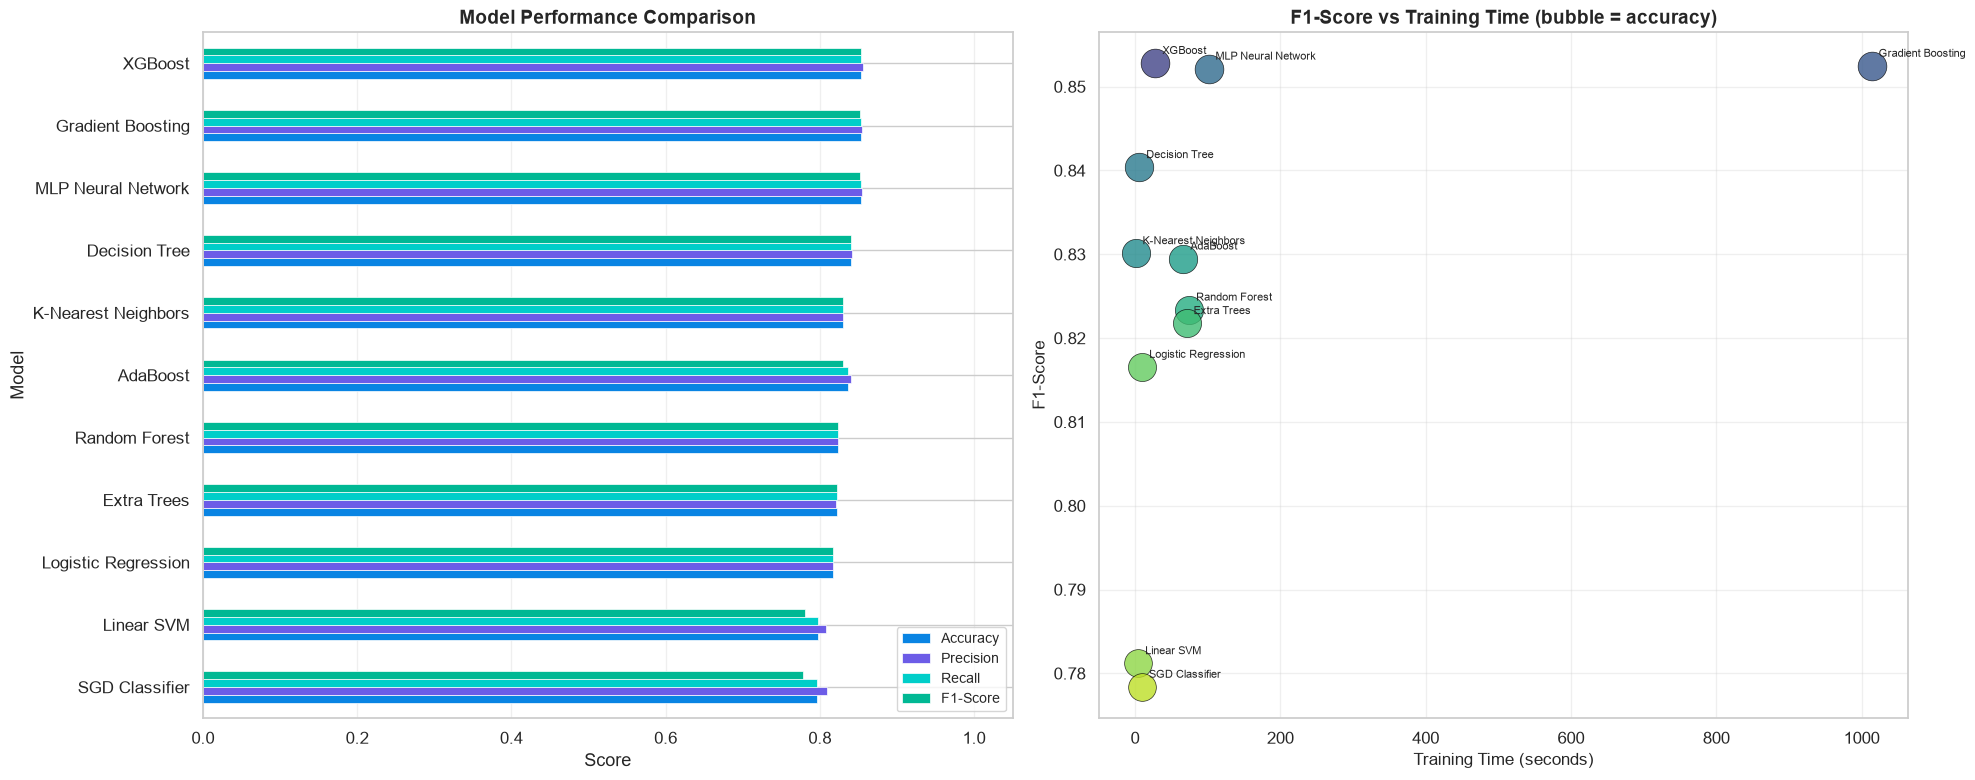

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# ── Chart 1: All metrics side by side ──
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
plot_df = results_df.set_index('Model')[metrics].sort_values('F1-Score', ascending=True)

colors_metrics = ['#0984E3', '#6C5CE7', '#00CEC9', '#00B894']
plot_df.plot(kind='barh', ax=axes[0], color=colors_metrics, edgecolor='white', linewidth=0.5)
axes[0].set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Score')
axes[0].set_xlim(0, 1.05)
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(axis='x', alpha=0.3)

# ── Chart 2: F1 vs Training Time (bubble chart) ──
ax2 = axes[1]
scatter_colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(results_df)))
for i, row in results_df.iterrows():
    ax2.scatter(row['Train Time (s)'], row['F1-Score'],
               s=row['Accuracy'] * 500, c=[scatter_colors[i-1]],
               edgecolors='black', linewidth=0.5, alpha=0.8)
    ax2.annotate(row['Model'], (row['Train Time (s)'], row['F1-Score']),
                 fontsize=8, ha='left', va='bottom', xytext=(5, 5),
                 textcoords='offset points')

ax2.set_title('F1-Score vs Training Time (bubble = accuracy)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Training Time (seconds)', fontsize=12)
ax2.set_ylabel('F1-Score', fontsize=12)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12 · Best Model — Deep Dive

In [22]:
# Identify best model by F1-Score
best_name = results_df.iloc[0]['Model']
best_pipeline = trained_pipelines[best_name]
best_f1 = results_df.iloc[0]['F1-Score']

print(f'🏆 Best Model: {best_name}')
print(f'   F1-Score: {best_f1:.4f}')
print(f'   Accuracy: {results_df.iloc[0]["Accuracy"]:.4f}')

🏆 Best Model: XGBoost
   F1-Score: 0.8528
   Accuracy: 0.8535


### 12.1 Confusion Matrix

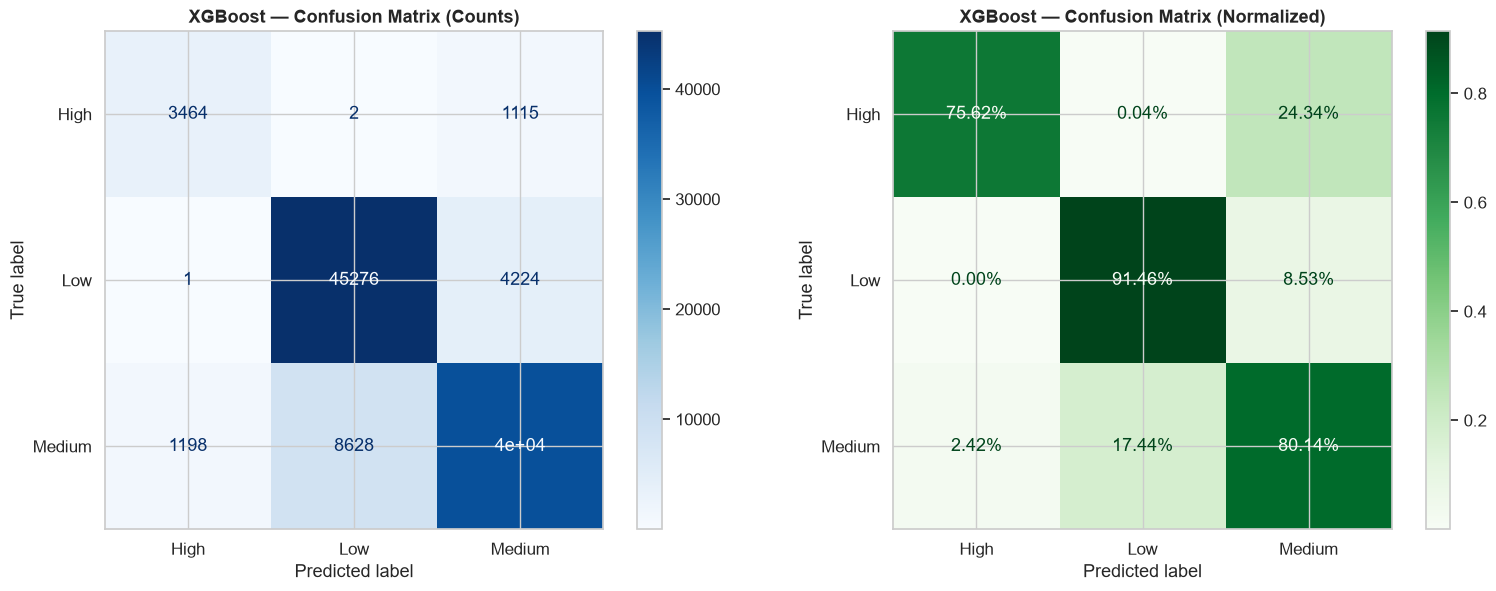

In [23]:
y_pred_best = best_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_).plot(ax=axes[0], cmap='Blues')
axes[0].set_title(f'{best_name} — Confusion Matrix (Counts)', fontsize=13, fontweight='bold')

# Normalized (percentages)
cm_norm = confusion_matrix(y_test, y_pred_best, normalize='true')
ConfusionMatrixDisplay(cm_norm, display_labels=label_encoder.classes_).plot(ax=axes[1], cmap='Greens', values_format='.2%')
axes[1].set_title(f'{best_name} — Confusion Matrix (Normalized)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### 12.2 Classification Report

In [24]:
print(f'Classification Report — {best_name}')
print('=' * 65)
print(classification_report(y_test, y_pred_best, target_names=label_encoder.classes_))

Classification Report — XGBoost
              precision    recall  f1-score   support

        High       0.74      0.76      0.75      4581
         Low       0.84      0.91      0.88     49501
      Medium       0.88      0.80      0.84     49469

    accuracy                           0.85    103551
   macro avg       0.82      0.82      0.82    103551
weighted avg       0.86      0.85      0.85    103551



### 12.3 Feature Importance

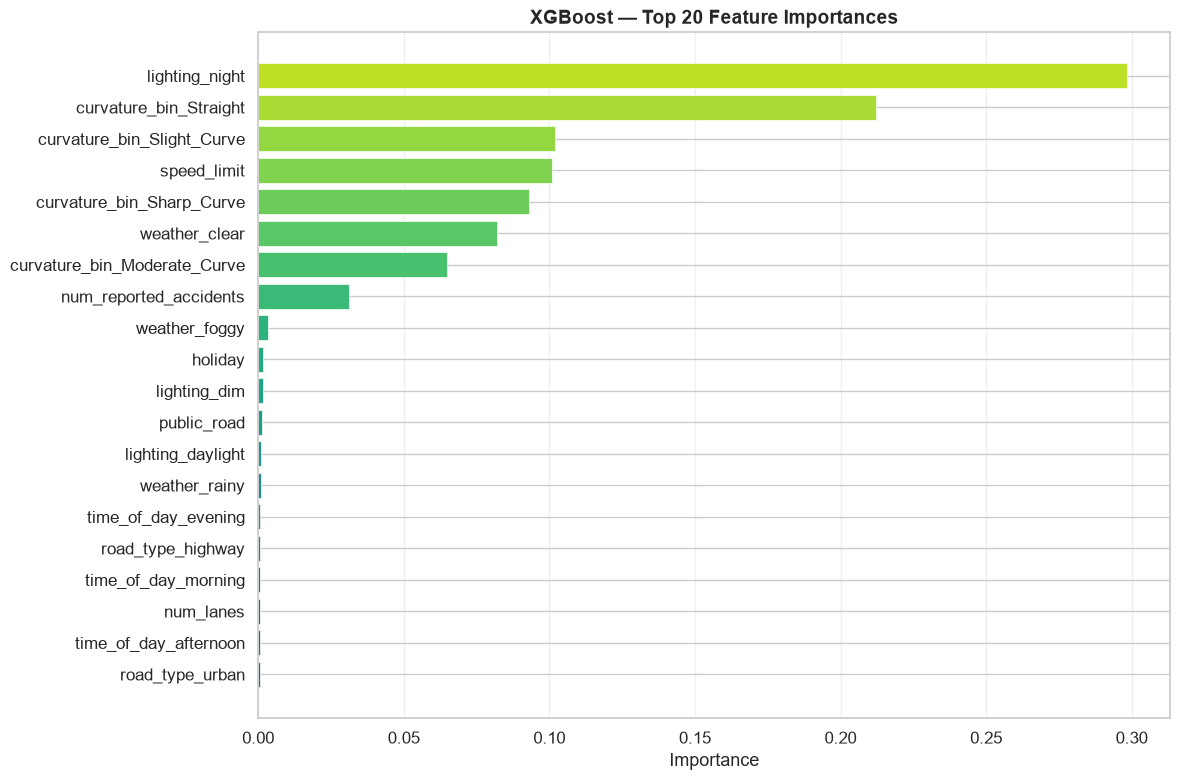

In [25]:
# Extract feature names from the fitted preprocessor
fitted_preprocessor = best_pipeline.named_steps['preprocessor']
cat_encoder = fitted_preprocessor.named_transformers_['cat']
cat_feature_names = list(cat_encoder.get_feature_names_out(categorical_features))
all_feature_names = cat_feature_names + numeric_features + boolean_features

# Try to get feature importance from the classifier
classifier = best_pipeline.named_steps['classifier']

if hasattr(classifier, 'feature_importances_'):
    importances = classifier.feature_importances_
    feat_imp = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': importances
    }).sort_values('Importance', ascending=True).tail(20)
    
    fig, ax = plt.subplots(figsize=(12, 8))
    bars = ax.barh(feat_imp['Feature'], feat_imp['Importance'],
                   color=plt.cm.viridis(np.linspace(0.3, 0.9, len(feat_imp))),
                   edgecolor='white', linewidth=0.5)
    ax.set_title(f'{best_name} — Top 20 Feature Importances', fontsize=14, fontweight='bold')
    ax.set_xlabel('Importance')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
elif hasattr(classifier, 'coef_'):
    # For linear models, use coefficient magnitudes
    coef_avg = np.abs(classifier.coef_).mean(axis=0)  # Average across classes
    feat_imp = pd.DataFrame({
        'Feature': all_feature_names,
        'Coefficient Magnitude': coef_avg
    }).sort_values('Coefficient Magnitude', ascending=True).tail(20)
    
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.barh(feat_imp['Feature'], feat_imp['Coefficient Magnitude'],
            color=plt.cm.plasma(np.linspace(0.3, 0.9, len(feat_imp))),
            edgecolor='white', linewidth=0.5)
    ax.set_title(f'{best_name} — Top 20 Feature Coefficients (abs)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Absolute Coefficient Magnitude')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print(f'{best_name} does not expose feature importances or coefficients.')

## 13 · Cross-Validation of Top 3 Models

We perform 5-fold stratified cross-validation on the top-3 models to confirm generalization.

Top 3 models: ['XGBoost', 'Gradient Boosting', 'MLP Neural Network']

▶ Cross-validating: XGBoost...
  F1 scores: [0.854  0.8531 0.8541 0.8558 0.8525]
  Mean: 0.8539 ± 0.0011

▶ Cross-validating: Gradient Boosting...
  F1 scores: [0.8542 0.8532 0.8538 0.8557 0.8526]
  Mean: 0.8539 ± 0.0011

▶ Cross-validating: MLP Neural Network...
  F1 scores: [0.8534 0.8521 0.8531 0.8546 0.852 ]
  Mean: 0.8530 ± 0.0009



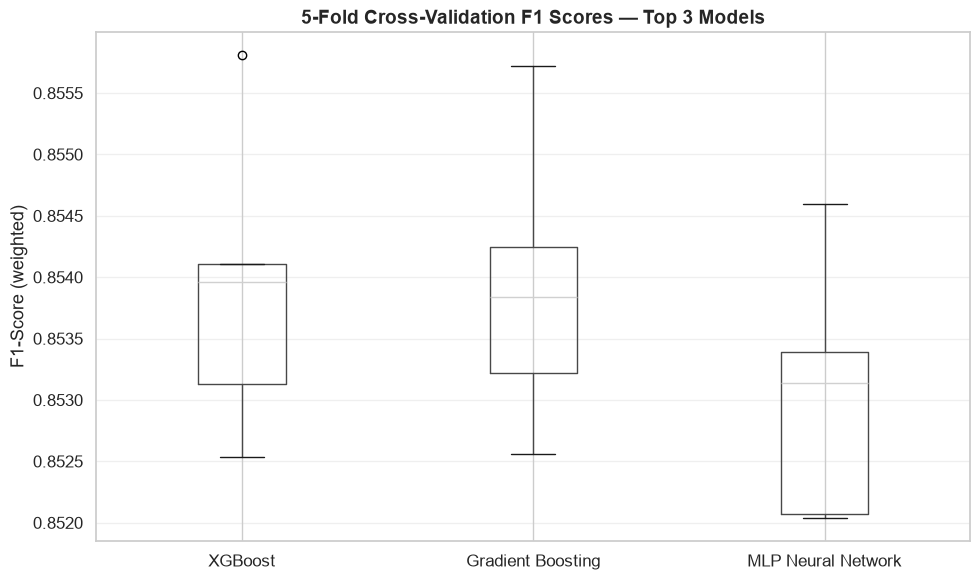

In [26]:
top3_names = results_df.head(3)['Model'].tolist()
print(f'Top 3 models: {top3_names}')
print()

cv_results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name in top3_names:
    print(f'▶ Cross-validating: {name}...')
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', models[name])
    ])
    scores = cross_val_score(pipeline, X, y, cv=skf, scoring='f1_weighted', n_jobs=-1)
    cv_results[name] = scores
    print(f'  F1 scores: {scores.round(4)}')
    print(f'  Mean: {scores.mean():.4f} ± {scores.std():.4f}')
    print()

# Boxplot comparison
fig, ax = plt.subplots(figsize=(10, 6))
cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(ax=ax, grid=True)
ax.set_title('5-Fold Cross-Validation F1 Scores — Top 3 Models', fontsize=14, fontweight='bold')
ax.set_ylabel('F1-Score (weighted)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 14 · Hyperparameter Tuning — Best Model

We fine-tune the best-performing model using `GridSearchCV` to squeeze out more performance.

In [27]:
# Define hyperparameter grids for common best-performing models
param_grids = {
    'Random Forest': {
        'classifier__n_estimators': [200, 300, 500],
        'classifier__max_depth': [15, 20, 25, None],
        'classifier__min_samples_split': [2, 5],
        'classifier__min_samples_leaf': [1, 2],
    },
    'Gradient Boosting': {
        'classifier__n_estimators': [200, 300],
        'classifier__max_depth': [4, 5, 7],
        'classifier__learning_rate': [0.05, 0.1, 0.2],
        'classifier__subsample': [0.8, 1.0],
    },
    'Extra Trees': {
        'classifier__n_estimators': [200, 300, 500],
        'classifier__max_depth': [15, 20, 25, None],
        'classifier__min_samples_split': [2, 5],
    },
    'XGBoost': {
        'classifier__n_estimators': [200, 300, 500],
        'classifier__max_depth': [5, 6, 8],
        'classifier__learning_rate': [0.05, 0.1, 0.2],
        'classifier__subsample': [0.8, 1.0],
    },
    'Logistic Regression': {
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__solver': ['lbfgs', 'saga'],
    },
    'MLP Neural Network': {
        'classifier__hidden_layer_sizes': [(128, 64, 32), (256, 128, 64), (128, 64)],
        'classifier__alpha': [0.0001, 0.001],
        'classifier__learning_rate_init': [0.001, 0.01],
    },
}

# Use a default generic grid if the best model isn't in our dictionary
if best_name in param_grids:
    search_grid = param_grids[best_name]
    print(f'Tuning {best_name} with grid:')
    for param, values in search_grid.items():
        print(f'  {param}: {values}')
else:
    print(f'No predefined grid for "{best_name}". Skipping tuning — using default model.')
    search_grid = None

Tuning XGBoost with grid:
  classifier__n_estimators: [200, 300, 500]
  classifier__max_depth: [5, 6, 8]
  classifier__learning_rate: [0.05, 0.1, 0.2]
  classifier__subsample: [0.8, 1.0]


In [28]:
from sklearn.model_selection import GridSearchCV

if search_grid is not None:
    tuning_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', models[best_name])
    ])
    
    grid_search = GridSearchCV(
        tuning_pipeline,
        param_grid=search_grid,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
        scoring='f1_weighted',
        n_jobs=-1,
        verbose=1
    )
    
    print(f'Starting GridSearchCV for {best_name}...')
    t0 = time.time()
    grid_search.fit(X_train, y_train)
    tune_time = time.time() - t0
    
    print(f'\nCompleted in {tune_time:.1f}s')
    print(f'Best params: {grid_search.best_params_}')
    print(f'Best CV F1: {grid_search.best_score_:.4f}')
    
    # Evaluate tuned model
    y_pred_tuned = grid_search.predict(X_test)
    tuned_f1 = f1_score(y_test, y_pred_tuned, average='weighted')
    tuned_acc = accuracy_score(y_test, y_pred_tuned)
    
    print(f'\nTuned Test Accuracy: {tuned_acc:.4f}')
    print(f'Tuned Test F1-Score: {tuned_f1:.4f}')
    print(f'Improvement over baseline: {(tuned_f1 - best_f1)*100:+.2f}%')
    
    # Update best pipeline if tuned is better
    if tuned_f1 >= best_f1:
        final_pipeline = grid_search.best_estimator_
        print('\n✓ Tuned model is the new best — using it for predictions.')
    else:
        final_pipeline = best_pipeline
        print('\n✗ Tuning did not improve — keeping original model.')
else:
    final_pipeline = best_pipeline
    print(f'Using {best_name} with default hyperparameters.')

Starting GridSearchCV for XGBoost...
Fitting 3 folds for each of 54 candidates, totalling 162 fits

Completed in 3717.3s
Best params: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 300, 'classifier__subsample': 0.8}
Best CV F1: 0.8542

Tuned Test Accuracy: 0.8534
Tuned Test F1-Score: 0.8527
Improvement over baseline: -0.01%

✗ Tuning did not improve — keeping original model.


### 14.1 Tuned Model — Confusion Matrix & Report

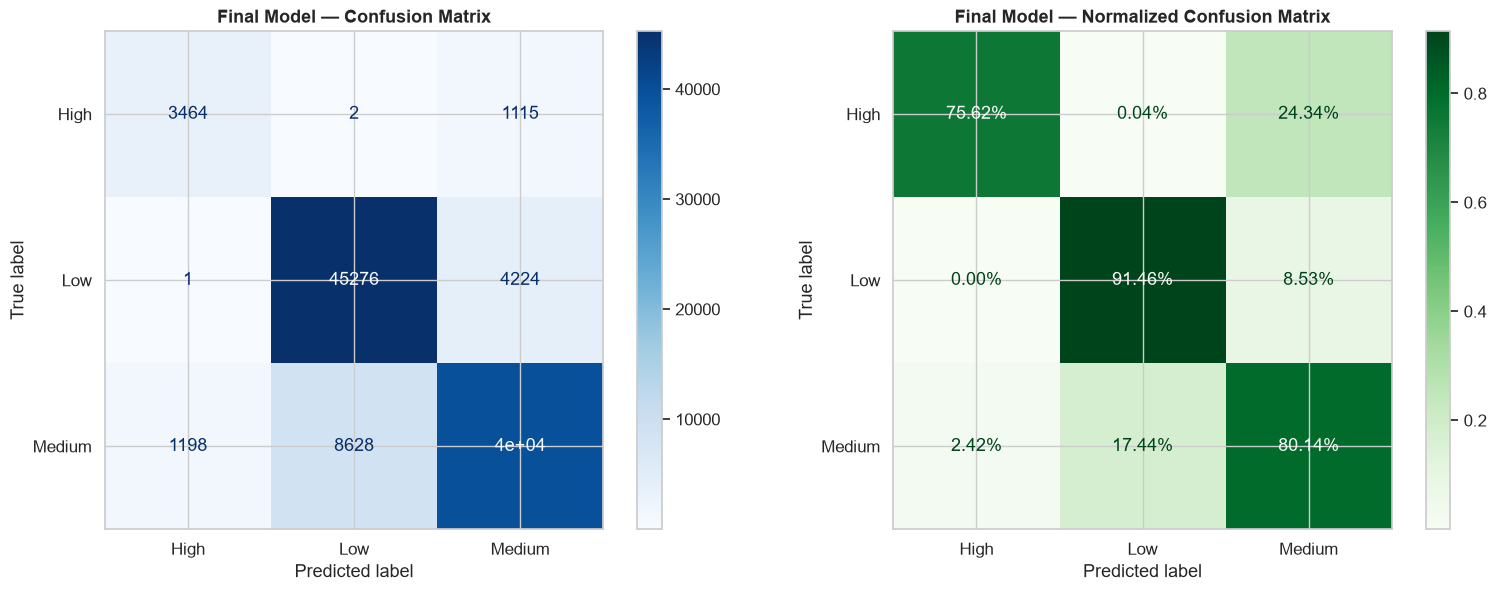


Final Classification Report:
              precision    recall  f1-score   support

        High       0.74      0.76      0.75      4581
         Low       0.84      0.91      0.88     49501
      Medium       0.88      0.80      0.84     49469

    accuracy                           0.85    103551
   macro avg       0.82      0.82      0.82    103551
weighted avg       0.86      0.85      0.85    103551



In [29]:
y_pred_final = final_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cm_final = confusion_matrix(y_test, y_pred_final)
ConfusionMatrixDisplay(cm_final, display_labels=label_encoder.classes_).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Final Model — Confusion Matrix', fontsize=13, fontweight='bold')

cm_norm_final = confusion_matrix(y_test, y_pred_final, normalize='true')
ConfusionMatrixDisplay(cm_norm_final, display_labels=label_encoder.classes_).plot(ax=axes[1], cmap='Greens', values_format='.2%')
axes[1].set_title('Final Model — Normalized Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print()
print('Final Classification Report:')
print('=' * 65)
print(classification_report(y_test, y_pred_final, target_names=label_encoder.classes_))

## 15 · Save Final Model

We save the trained pipeline + label encoder so it can be loaded later for predictions.

In [ ]:
# Save the final pipeline and label encoder
joblib.dump(final_pipeline, 'models/accident_severity_model.pkl')
joblib.dump(label_encoder, 'models/severity_label_encoder.pkl')

print('Model saved:')
print('  accident_severity_model.pkl')
print('  severity_label_encoder.pkl')

Model saved:
  accident_severity_model.pkl
  severity_label_encoder.pkl


## 16 · 🎮 Interactive Prediction

Run the cell below to input road/environment properties and get a severity prediction.

- For **categorical** features: choose from the numbered options
- For **numeric** features: type a value directly
- For **yes/no** features: type `y` or `n`

In [31]:
def get_user_input():
    """Collect user inputs for all features and return a prediction-ready DataFrame."""
    print('╔' + '═' * 60 + '╗')
    print('║   🎯 ACCIDENT SEVERITY PREDICTION — Interactive Input     ║')
    print('╚' + '═' * 60 + '╝')
    print()
    
    # ── road_type ──
    print('1. ROAD TYPE:')
    road_options = ['highway', 'rural', 'urban']
    for i, opt in enumerate(road_options, 1):
        print(f'   {i}. {opt}')
    choice = int(input('   Enter choice (1-3): ')) - 1
    road_type = road_options[choice]
    print(f'   → Selected: {road_type}')
    print()
    
    # ── curvature ──
    print('2. ROAD CURVATURE:')
    curv_options = ['Straight', 'Slight_Curve', 'Moderate_Curve', 'Sharp_Curve']
    curv_descriptions = [
        'Straight (nearly no curve, 0–20%)',
        'Slight Curve (gentle bend, 21–50%)',
        'Moderate Curve (noticeable curve, 51–80%)',
        'Sharp Curve (tight/dangerous curve, 81–100%)'
    ]
    for i, desc in enumerate(curv_descriptions, 1):
        print(f'   {i}. {desc}')
    choice = int(input('   Enter choice (1-4): ')) - 1
    curvature_bin = curv_options[choice]
    print(f'   → Selected: {curvature_bin}')
    print()
    
    # ── num_lanes ──
    print('3. NUMBER OF LANES:')
    for i in range(1, 5):
        print(f'   {i}. {i} lane(s)')
    num_lanes = int(input('   Enter choice (1-4): '))
    print(f'   → Selected: {num_lanes}')
    print()
    
    # ── speed_limit ──
    print('4. SPEED LIMIT (mph):')
    speed_options = [25, 35, 45, 60, 70]
    for i, spd in enumerate(speed_options, 1):
        print(f'   {i}. {spd} mph')
    choice = int(input('   Enter choice (1-5): ')) - 1
    speed_limit = speed_options[choice]
    print(f'   → Selected: {speed_limit} mph')
    print()
    
    # ── lighting ──
    print('5. LIGHTING CONDITIONS:')
    light_options = ['daylight', 'dim', 'night']
    for i, opt in enumerate(light_options, 1):
        print(f'   {i}. {opt}')
    choice = int(input('   Enter choice (1-3): ')) - 1
    lighting = light_options[choice]
    print(f'   → Selected: {lighting}')
    print()
    
    # ── weather ──
    print('6. WEATHER CONDITIONS:')
    weather_options = ['clear', 'foggy', 'rainy']
    for i, opt in enumerate(weather_options, 1):
        print(f'   {i}. {opt}')
    choice = int(input('   Enter choice (1-3): ')) - 1
    weather = weather_options[choice]
    print(f'   → Selected: {weather}')
    print()
    
    # ── time_of_day ──
    print('7. TIME OF DAY:')
    time_options = ['morning', 'afternoon', 'evening']
    for i, opt in enumerate(time_options, 1):
        print(f'   {i}. {opt}')
    choice = int(input('   Enter choice (1-3): ')) - 1
    time_of_day = time_options[choice]
    print(f'   → Selected: {time_of_day}')
    print()
    
    # ── Boolean features ──
    print('8. YES / NO QUESTIONS (enter y or n):')
    road_signs = 1 if input('   Road signs present? (y/n): ').strip().lower() == 'y' else 0
    public_road = 1 if input('   Public road? (y/n): ').strip().lower() == 'y' else 0
    holiday = 1 if input('   Holiday? (y/n): ').strip().lower() == 'y' else 0
    school_season = 1 if input('   School season? (y/n): ').strip().lower() == 'y' else 0
    print()
    
    # ── num_reported_accidents ──
    print('9. NUMBER OF PRIOR REPORTED ACCIDENTS (0–7):')
    num_accidents = int(input('   Enter value (0-7): '))
    num_accidents = max(0, min(7, num_accidents))  # Clamp to valid range
    print(f'   → Selected: {num_accidents}')
    print()
    
    # Build the input row
    input_data = pd.DataFrame([{
        'road_type': road_type,
        'curvature_bin': curvature_bin,
        'num_lanes': num_lanes,
        'speed_limit': speed_limit,
        'lighting': lighting,
        'weather': weather,
        'road_signs_present': road_signs,
        'public_road': public_road,
        'time_of_day': time_of_day,
        'holiday': holiday,
        'school_season': school_season,
        'num_reported_accidents': num_accidents,
    }])
    
    return input_data

print('Interactive prediction function defined ✓')
print('Run the next cell to start the prediction interface.')

Interactive prediction function defined ✓
Run the next cell to start the prediction interface.


In [32]:
# ══════════════════════════════════════════════════
#  RUN THIS CELL TO MAKE A PREDICTION
# ══════════════════════════════════════════════════

user_input = get_user_input()

# Predict
prediction_encoded = final_pipeline.predict(user_input)[0]
prediction_label = label_encoder.inverse_transform([prediction_encoded])[0]

# Get prediction probabilities if available
severity_emoji = {'Low': '🟢', 'Medium': '🟡', 'High': '🔴'}

print('╔' + '═' * 60 + '╗')
print('║               📋 PREDICTION RESULT                        ║')
print('╠' + '═' * 60 + '╣')
print(f'║  Predicted Severity: {severity_emoji.get(prediction_label, "")} {prediction_label:<35} ║')

if hasattr(final_pipeline.named_steps['classifier'], 'predict_proba'):
    probas = final_pipeline.predict_proba(user_input)[0]
    print('║' + ' ' * 60 + '║')
    print('║  Class Probabilities:' + ' ' * 38 + '║')
    for cls_idx, cls_name in enumerate(label_encoder.classes_):
        bar_len = int(probas[cls_idx] * 30)
        bar = '█' * bar_len + '░' * (30 - bar_len)
        prob_str = f'    {severity_emoji.get(cls_name, "")} {cls_name:<8} {bar} {probas[cls_idx]*100:5.1f}%'
        print(f'║  {prob_str:<57} ║')

print('╚' + '═' * 60 + '╝')

print()
print('Input summary:')
print(user_input.to_string(index=False))

╔════════════════════════════════════════════════════════════╗
║   🎯 ACCIDENT SEVERITY PREDICTION — Interactive Input     ║
╚════════════════════════════════════════════════════════════╝

1. ROAD TYPE:
   1. highway
   2. rural
   3. urban
   → Selected: highway

2. ROAD CURVATURE:
   1. Straight (nearly no curve, 0–20%)
   2. Slight Curve (gentle bend, 21–50%)
   3. Moderate Curve (noticeable curve, 51–80%)
   4. Sharp Curve (tight/dangerous curve, 81–100%)
   → Selected: Straight

3. NUMBER OF LANES:
   1. 1 lane(s)
   2. 2 lane(s)
   3. 3 lane(s)
   4. 4 lane(s)
   → Selected: 3

4. SPEED LIMIT (mph):
   1. 25 mph
   2. 35 mph
   3. 45 mph
   4. 60 mph
   5. 70 mph
   → Selected: 70 mph

5. LIGHTING CONDITIONS:
   1. daylight
   2. dim
   3. night
   → Selected: night

6. WEATHER CONDITIONS:
   1. clear
   2. foggy
   3. rainy
   → Selected: clear

7. TIME OF DAY:
   1. morning
   2. afternoon
   3. evening
   → Selected: evening

8. YES / NO QUESTIONS (enter y or n):

9. NUMBER OF 

## 17 · Quick Prediction (Non-Interactive)

You can also call `predict_severity(...)` directly without interactive prompts:

In [33]:
def predict_severity(road_type, curvature_bin, num_lanes, speed_limit,
                     lighting, weather, time_of_day,
                     road_signs_present, public_road,
                     holiday, school_season, num_reported_accidents):
    """
    Predict accident severity from road/environment features.
    
    Parameters:
    ----------
    road_type : str — 'highway', 'rural', or 'urban'
    curvature_bin : str — 'Straight', 'Slight_Curve', 'Moderate_Curve', or 'Sharp_Curve'
    num_lanes : int — 1 to 4
    speed_limit : int — 25, 35, 45, 60, or 70
    lighting : str — 'daylight', 'dim', or 'night'
    weather : str — 'clear', 'foggy', or 'rainy'
    time_of_day : str — 'morning', 'afternoon', or 'evening'
    road_signs_present : bool or int (1/0)
    public_road : bool or int (1/0)
    holiday : bool or int (1/0)
    school_season : bool or int (1/0)
    num_reported_accidents : int — 0 to 7
    
    Returns:
    -------
    str — Predicted severity: 'Low', 'Medium', or 'High'
    """
    row = pd.DataFrame([{
        'road_type': road_type,
        'curvature_bin': curvature_bin,
        'num_lanes': int(num_lanes),
        'speed_limit': int(speed_limit),
        'lighting': lighting,
        'weather': weather,
        'time_of_day': time_of_day,
        'road_signs_present': int(road_signs_present),
        'public_road': int(public_road),
        'holiday': int(holiday),
        'school_season': int(school_season),
        'num_reported_accidents': int(num_reported_accidents),
    }])
    
    pred_encoded = final_pipeline.predict(row)[0]
    pred_label = label_encoder.inverse_transform([pred_encoded])[0]
    return pred_label

# ── Example predictions ──
print('Example predictions:')
print()

# Scenario 1: Safe conditions
pred1 = predict_severity('urban', 'Straight', 2, 25, 'daylight', 'clear', 'morning',
                         True, True, False, True, 0)
print(f'  🏙️ Urban, straight road, 25mph, daylight, clear weather → {pred1}')

# Scenario 2: Moderate risk
pred2 = predict_severity('rural', 'Moderate_Curve', 2, 60, 'dim', 'rainy', 'evening',
                         True, True, False, True, 3)
print(f'  🌧️ Rural, moderate curve, 60mph, dim, rainy evening → {pred2}')

# Scenario 3: Dangerous conditions
pred3 = predict_severity('highway', 'Sharp_Curve', 1, 70, 'night', 'foggy', 'evening',
                         False, True, True, False, 6)
print(f'  🌫️ Highway, sharp curve, 70mph, night, foggy → {pred3}')

Example predictions:

  🏙️ Urban, straight road, 25mph, daylight, clear weather → Low
  🌧️ Rural, moderate curve, 60mph, dim, rainy evening → Medium
  🌫️ Highway, sharp curve, 70mph, night, foggy → High
